# SQL 1: Introduction

**Seong Cho** · ACME Data Science Essentials, Lab 1

**Lab objective:** store and manipulate tabular data with SQL, using Python's standard `sqlite3` module to create, read, update, and delete database tables.

<sub>Lab specification from the 2017 *Volume 2* version of this lab, which later became Lab 1 of the *Data Science Essentials* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from that 2017 version; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
# sql1.py
# """Volume 3: SQL 1 (Introduction).
# <Name>
# <Class>
# <Date>
# """
import numpy as np
import matplotlib.pyplot as plt
import sqlite3 as sql
import csv

## Relational databases

A **relational database** is a collection of tables (**relations**). Each row is a **tuple** (one instance of the data), each column an **attribute** (feature), and the list of column headings is the table's **schema**. A table with schema `(Name, Gender, Age)` holding $M$ people is $M \times 3$.

## SQLite in Python

Python's standard-library `sqlite3` module implements SQLite, the most common SQL variant in Python. A database lives in an external file (usually `.db`), which should never be opened with `open()`. Every interaction follows the same pattern:

1. `sql.connect(file)` opens a connection (creating the file if needed);
2. `conn.cursor()` gets a cursor, the object that traverses the database;
3. `cur.execute("<SQL command>")` reads or alters data;
4. `conn.commit()` saves changes (`conn.rollback()` reverts them);
5. `conn.close()` closes the connection.

Using `with sql.connect(...) as conn:` commits automatically on success and rolls back on an error, but does **not** close the connection, so wrap it in `try ... finally: conn.close()`.

> **Achtung!** Some changes, such as creating and deleting tables, are committed automatically by `execute()`; deleting a table is immediate and permanent. Most other changes only reach the file on `commit()`, so don't close the connection before committing.

## Managing tables

SQLite has five native types, matching Python types: `NULL` (`None`), `INTEGER` (`int`), `REAL` (`float`), `TEXT` (`str`), `BLOB` (`bytes`). Though SQLite doesn't force one type per column, most SQL systems do, so specify types in the schema.

| Operation | SQLite command |
|---|---|
| Create a new table | `CREATE TABLE <table> (<schema>);` |
| Delete a table | `DROP TABLE <table>;` |
| Delete a table if it exists | `DROP TABLE IF EXISTS <table>;` |
| Add a new column | `ALTER TABLE <table> ADD <column> <dtype>` |
| Remove a column | `ALTER TABLE <table> DROP COLUMN <column>;` |

Creating a table that already exists, or dropping one that doesn't, raises an error; `DROP TABLE IF EXISTS` avoids the latter.

> **Note.** SQL keywords are written in capitals only by convention: SQLite is case insensitive. The trailing semicolon is optional in Python's interface but required by most other systems, so it is good practice to include it.

## Problem 1: Create the student tables

> **Problem 1.** Write a function that accepts the name of a database file. Connect to the database (and create it if it doesn't exist). Drop the tables `MajorInfo`, `CourseInfo`, `StudentInfo`, and `StudentGrades` from the database if they exist. Next, add the following tables to the database with the specified column names and types.
> - `MajorInfo`: `MajorID` (integers) and `MajorName` (strings).
> - `CourseInfo`: `CourseID` (integers) and `CourseName` (strings).
> - `StudentInfo`: `StudentID` (integers), `StudentName` (strings), and `MajorID` (integers).
> - `StudentGrades`: `StudentID` (integers), `CourseID` (integers), and `Grade` (strings).
>
> Remember to commit and close the database. You should be able to execute your function more than once with the same input without raising an error.

## Inserting data

`INSERT INTO <table> VALUES(...);` adds a tuple, matching values to the schema in order; the columns can also be named explicitly, as in `INSERT INTO MyTable(Name, ID, Age) VALUES(...)`. To insert many rows at once, `cur.executemany()` with a list of tuples is much faster than calling `execute()` in a loop.

> **Achtung!** Never build a SQL command from variables with Python string operations: that invites a SQL injection attack. Use parameter substitution instead: put `?` in the command and pass the values as a second argument, e.g. `cur.execute("INSERT INTO MyTable VALUES(?,?,?);", values)`.

A CSV file can be read like a text file or with the `csv` module: `rows = list(csv.reader(infile))`.

## Problem 2: Populate the tables

> **Problem 2.** Expand your function from Problem 1 so that it populates the tables with the data given in Tables 1.2a–1.2d.
>
> | MajorID | MajorName |
> |---|---|
> | 1 | Math |
> | 2 | Science |
> | 3 | Writing |
> | 4 | Art |
>
> | CourseID | CourseName |
> |---|---|
> | 1 | Calculus |
> | 2 | English |
> | 3 | Pottery |
> | 4 | History |
>
> *(Tables 1.2c and 1.2d, `StudentInfo` and `StudentGrades`, are omitted here.)*
>
> The `StudentInfo` and `StudentGrades` tables are also recorded in `student_info.csv` and `student_grades.csv`, respectively, with `NULL` values represented as $-1$.

## Problem 3: Earthquake table

> **Problem 3.** The data file `us_earthquakes.csv` contains data from about 3,500 earthquakes in the United States since the 1769. Each row records the year, month, day, hour, minute, second, latitude, longitude, and magnitude of a single earthquake (in that order). Note that latitude, longitude, and magnitude are floats, while the remaining columns are integers.
>
> Write a function that accepts the name of a database file. Drop the table `USEarthquakes` if it already exists, then create a new `USEarthquakes` table with schema `(Year, Month, Day, Hour, Minute, Second, Latitude, Longitude, Magnitude)`. Populate the table with the data from `us_earthquakes.csv`. Remember to commit the changes and close the connection. (Hint: using `executemany()` is much faster than using `execute()` in a loop.)

## The WHERE clause

`WHERE <condition>` filters rows by a boolean predicate built from `==, !=, <, >, <=, >=, AND, OR, NOT`. It is what makes deleting and updating safe; without it, `DELETE` or `UPDATE` hits every row.

| Operation | SQLite command |
|---|---|
| Add a new row | `INSERT INTO table VALUES(<values>);` |
| Remove rows | `DELETE FROM <table> WHERE <condition>;` |
| Change values in existing rows | `UPDATE <table> SET <column1>=<value1>, ... WHERE <condition>;` |

## Problem 4: Clean up with WHERE

> **Problem 4.** Modify your function from Problems 1 and 2 so that in the `StudentInfo` table, values of $-1$ in the `MajorID` column are replaced with `NULL` values.
>
> Also modify your function from Problem 3 in the following ways.
> 1. Remove rows from `USEarthquakes` that have a value of 0 for the `Magnitude`.
> 2. Replace 0 values in the `Day`, `Hour`, `Minute`, and `Second` columns with `NULL` values.

`student_db()` answers Problems 1, 2 and the first part of Problem 4; `earthquakes_db()` answers Problem 3 and the rest of Problem 4. Running them (re)creates `students.db` and `earthquakes.db` from the CSV files.

In [2]:
# Problems 1, 2, and 4
def student_db(db_file="students.db", student_info="student_info.csv",
                                      student_grades="student_grades.csv"):
    """Connect to the database db_file (or create it if it doesn’t exist).
    Drop the tables MajorInfo, CourseInfo, StudentInfo, and StudentGrades from
    the database (if they exist). Recreate the following (empty) tables in the
    database with the specified columns.

        - MajorInfo: MajorID (integers) and MajorName (strings).
        - CourseInfo: CourseID (integers) and CourseName (strings).
        - StudentInfo: StudentID (integers), StudentName (strings), and
            MajorID (integers).
        - StudentGrades: StudentID (integers), CourseID (integers), and
            Grade (strings).

    Next, populate the new tables with the following data and the data in
    the specified 'student_info' 'student_grades' files.

                MajorInfo                         CourseInfo
            MajorID | MajorName               CourseID | CourseName
            -------------------               ---------------------
                1   | Math                        1    | Calculus
                2   | Science                     2    | English
                3   | Writing                     3    | Pottery
                4   | Art                         4    | History

    Finally, in the StudentInfo table, replace values of −1 in the MajorID
    column with NULL values.

    Parameters:
        db_file (str): The name of the database file.
        student_info (str): The name of a csv file containing data for the
            StudentInfo table.
        student_grades (str): The name of a csv file containing data for the
            StudentGrades table.
    """
    try:
        with sql.connect(db_file) as conn:
            cur = conn.cursor()
            cur.execute("DROP TABLE IF EXISTS MajorInfo")
            cur.execute("DROP TABLE IF EXISTS CourseInfo")
            cur.execute("DROP TABLE IF EXISTS StudentInfo")
            cur.execute("DROP TABLE IF EXISTS StudentGrades")
            cur.execute("CREATE TABLE MajorInfo (MajorID INTEGER, MajorName TEXT)")
            cur.execute("CREATE TABLE CourseInfo (CourseID INTEGER, CourseName TEXT)")
            cur.execute("CREATE TABLE StudentInfo (StudentID INTEGER, StudentName TEXT, MajorID INTEGER)")
            cur.execute("CREATE TABLE StudentGrades (StudentID INTEGER, CourseID INTEGER, Grade TEXT)")
            MajorInfoRows = [(1, 'Math'), (2, 'Science'), (3, 'Writing'), (4, 'Art')]
            CourseInfoRows = [(1, 'Calculus'), (2, 'English'), (3, 'Pottery'), (4, 'History')]
            with open(student_info, 'r') as infile:
                StudentInfoRows = list(csv.reader(infile))
            with open(student_grades, 'r') as infile:
                StudentGradesRows = list(csv.reader(infile))                
            cur.executemany("INSERT INTO MajorInfo VALUES(?,?);", MajorInfoRows)
            cur.executemany("INSERT INTO CourseInfo VALUES(?,?);", CourseInfoRows)
            cur.executemany("INSERT INTO StudentInfo VALUES(?,?,?);", StudentInfoRows)
            cur.executemany("INSERT INTO StudentGrades VALUES(?,?,?);", StudentGradesRows)
            cur.execute("UPDATE StudentInfo SET MajorID=NULL WHERE MajorID==-1;")

    finally:
        conn.close()

In [3]:
# Problems 3 and 4
def earthquakes_db(db_file="earthquakes.db", data_file="us_earthquakes.csv"):
    """Connect to the database db_file (or create it if it doesn’t exist).
    Drop the USEarthquakes table if it already exists, then create a new
    USEarthquakes table with schema
    (Year, Month, Day, Hour, Minute, Second, Latitude, Longitude, Magnitude).
    Populate the table with the data from 'data_file'.

    For the Minute, Hour, Second, and Day columns in the USEarthquakes table,
    change all zero values to NULL. These are values where the data originally
    was not provided.

    Parameters:
        db_file (str): The name of the database file.
        data_file (str): The name of a csv file containing data for the
            USEarthquakes table.
    """
    try:
        with sql.connect(db_file) as conn:
            cur = conn.cursor()
            cur.execute("DROP TABLE IF EXISTS USEarthquakes")
            cur.execute("CREATE TABLE USEarthquakes " +
                        "(Year INTEGER, Month INTEGER, Day INTEGER, Hour INTEGER," +
                        " Minute INTEGER, Second INTEGER, Latitude REAL, Longitude REAL, Magnitude REAL)")
            with open(data_file, 'r') as infile:
                rows = list(csv.reader(infile))
            cur.executemany("INSERT INTO USEarthquakes VALUES(?,?,?,?,?,?,?,?,?)", rows)
            cur.execute("DELETE FROM USEarthquakes WHERE Magnitude==0;")
            cur.execute("UPDATE USEarthquakes SET Day=NULL WHERE Day==0;")
            cur.execute("UPDATE USEarthquakes SET Hour=NULL WHERE Hour==0;")
            cur.execute("UPDATE USEarthquakes SET Minute=NULL WHERE Minute==0;")
            cur.execute("UPDATE USEarthquakes SET Second=NULL WHERE Second==0;")

    finally:
        conn.close()

In [4]:
# Helper for printing every row of the tables in a database.
def testdrive(database="students.db"):
    tables = list()
    if database == "students.db":
        tables += ["MajorInfo", "CourseInfo", "StudentInfo", "StudentGrades"]
    else:
        tables += ["USEarthquakes"]
    with sql.connect(database) as conn:
        cur = conn.cursor()
        for t in tables:
            rows = cur.execute("SELECT * FROM " + t + ";")
            print([d[0] for d in cur.description])
            for row in rows:
                print(row)
            print()

    conn.close()

In [5]:
student_db()
testdrive("students.db")

['MajorID', 'MajorName']
(1, 'Math')
(2, 'Science')
(3, 'Writing')
(4, 'Art')

['CourseID', 'CourseName']
(1, 'Calculus')
(2, 'English')
(3, 'Pottery')
(4, 'History')

['StudentID', 'StudentName', 'MajorID']
(401767594, 'Michelle Fernandez', 1)
(678665086, 'Gilbert Chapman', None)
(553725811, 'Roberta Cook', 2)
(886308195, 'Rene Cross', 3)
(103066521, 'Cameron Kim', 4)
(821568627, 'Mercedes Hall', None)
(206208438, 'Kristopher Tran', 2)
(341324754, 'Cassandra Holland', 1)
(262019426, 'Alfonso Phelps', None)
(622665098, 'Sammy Burke', 2)

['StudentID', 'CourseID', 'Grade']
(401767594, 4, 'C')
(401767594, 3, 'B-')
(678665086, 4, 'A+')
(678665086, 3, 'A+')
(553725811, 2, 'C')
(678665086, 1, 'B')
(886308195, 1, 'A')
(103066521, 2, 'C')
(103066521, 3, 'C-')
(821568627, 4, 'D')
(821568627, 2, 'A+')
(821568627, 1, 'B')
(206208438, 2, 'A')
(206208438, 1, 'C+')
(341324754, 2, 'D-')
(341324754, 1, 'A-')
(103066521, 4, 'A')
(262019426, 2, 'B')
(262019426, 3, 'C')
(622665098, 1, 'A')
(622665098, 2

In [6]:
earthquakes_db()
with sql.connect("earthquakes.db") as conn:
    cur = conn.cursor()
    print(cur.execute("SELECT COUNT(*) FROM USEarthquakes;").fetchone())
    for row in cur.execute("SELECT * FROM USEarthquakes LIMIT 5;"):
        print(row)
conn.close()

(3567,)
(1769, 7, 28, None, None, None, 33.9, -117.8, 6.0)
(1774, 5, 11, 15, None, None, 37.2, -77.4, 4.5)
(1783, 12, 14, 14, None, None, 41.0, -74.5, 5.3)
(1801, 2, 18, 18, None, None, 33.0, -117.3, 6.5)
(1804, 11, 11, 18, None, None, 42.0, -87.8, 4.4)


## Reading data

A **query** reads all or part of a database without modifying it. Queries start with `SELECT <columns> FROM <table>` plus optional conditions; `*` selects every column. The matching tuples, the **result set**, are read through the cursor:

| Method | Description |
|---|---|
| `execute()` | Execute a single SQL command |
| `executemany()` | Execute a single SQL command over different values |
| `executescript()` | Execute a SQL script (multiple SQL commands) |
| `fetchone()` | Return a single tuple from the result set |
| `fetchmany(n)` | Return the next `n` rows from the result set as a list of tuples |
| `fetchall()` | Return the entire result set as a list of tuples |

When a condition involves columns from several tables, give each table an alias with `AS` and refer to columns as `alias.column`, e.g. `SELECT SI.StudentName FROM StudentInfo AS SI, MajorInfo AS MI WHERE SI.MajorID == MI.MajorID AND MI.MajorName == 'Math'`.

## Problem 5: Top grades

> **Problem 5.** Write a function that accepts the name of a database file. Assuming the database to be in the format of the one created in Problems 1 and 2, query the database for all tuples of the form `(StudentName, CourseName)` where that student has an "A" or "A+" grade in that course. Return the list of tuples.

In [7]:
# Problem 5
def prob5(db_file="students.db"):
    """Query the database for all tuples of the form (StudentName, CourseName)
    where that student has an 'A' or 'A+'' grade in that course. Return the
    list of tuples.

    Parameters:
        db_file (str): the name of the database to connect to.

    Returns:
        (list): the complete result set for the query.
    """
    try:
        with sql.connect(db_file) as conn:
            cur = conn.cursor()
            cur.execute("SELECT SI.StudentName, CI.CourseName "
                        "FROM StudentInfo AS SI, StudentGrades AS SG, CourseInfo as CI "
                        "WHERE SI.StudentID == SG.StudentID AND SG.CourseID == CI.CourseID AND SG.Grade == 'A' "
                        "OR SI.StudentID == SG.StudentID AND SG.CourseID == CI.CourseID AND SG.Grade == 'A+';")
            return cur.fetchall()

    finally:
        conn.close()

In [8]:
prob5()

[('Gilbert Chapman', 'History'),
 ('Gilbert Chapman', 'Pottery'),
 ('Rene Cross', 'Calculus'),
 ('Cameron Kim', 'History'),
 ('Mercedes Hall', 'English'),
 ('Kristopher Tran', 'English'),
 ('Sammy Burke', 'Calculus')]

## Aggregate functions

SQL computes a few basic statistics itself: `AVG()`, `MIN()`, `MAX()`, `SUM()`, and `COUNT()` collapse a column of the result set into a single value, e.g. `SELECT COUNT(StudentName), MIN(StudentID) FROM StudentInfo;` gives `[(10, 103066521)]`.

## Problem 6: Earthquake magnitudes

> **Problem 6.** Write a function that accepts the name of a database file. Assuming the database to be in the format of the one created in Problem 3, query the `USEarthquakes` table for the following information.
> - The magnitudes of the earthquakes during the 19th century (1800–1899).
> - The magnitudes of the earthquakes during the 20th century (1900–1999).
> - The average magnitude of all earthquakes in the database.
>
> Create a single figure with two subplots: a histogram of the magnitudes of the earthquakes in the 19th century, and a histogram of the magnitudes of the earthquakes in the 20th century. Show the figure, then return the average magnitude of all of the earthquakes in the database. Be sure to return an actual number, not a list or a tuple.
>
> (Hint: use `np.ravel()` to convert a result set of 1-tuples to a 1-D array.)

In [9]:
# Problem 6
def prob6(db_file="earthquakes.db"):
    """Create a single figure with two subplots: a histogram of the magnitudes
    of the earthquakes from 1800-1900, and a histogram of the magnitudes of the
    earthquakes from 1900-2000. Also calculate and return the average magnitude
    of all of the earthquakes in the database.

    Parameters:
        db_file (str): the name of the database to connect to.

    Returns:
        (float): The average magnitude of all earthquakes in the database.
    """
    conn = sql.connect(db_file)
    cur = conn.cursor()
    cur.execute("SELECT Magnitude FROM USEarthquakes WHERE Year >= 1800 AND Year < 1900")
    EQ19 = np.ravel(cur.fetchall())
    cur.execute("SELECT Magnitude FROM USEarthquakes WHERE Year >= 1900 AND Year < 2000")
    EQ20 = np.ravel(cur.fetchall())
    cur.execute("SELECT AVG(Magnitude) FROM USEarthquakes")
    AM = np.ravel(cur.fetchall())[0]
    conn.close()
    
    plt.ion()
    ax1 = plt.subplot(121)
    ax1.hist(EQ19)
    ax1.set_ylabel("count")
    ax1.set_xlabel("Magnitude")
    ax1.set_title("19th Century Earthquakes")

    ax2 = plt.subplot(122)
    ax2.hist(EQ20)
    ax2.set_xlabel("Magnitude")
    ax2.set_title("20th Century Earthquakes")

    return AM

np.float64(5.247771236333053)

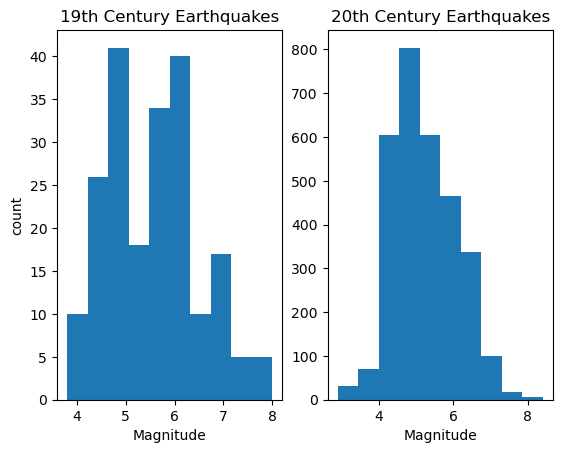

In [10]:
prob6()

> **Note.** Only 3 earthquakes were recorded (in this data set) from 1700–1799, 208 from 1800–1899, and 3049 from 1900–1999. Whether that reflects more earthquakes or better detection, the best answer without more research is "probably both": question how data was gathered and what biases it may carry before drawing strong conclusions.